# 📊 Khám phá dữ liệu tuyển dụng TopCV
Notebook này đọc file `raw_data.csv` và phân tích sơ bộ dữ liệu thu thập được.

## 1. Import thư viện & đọc dữ liệu

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib

# Hiển thị font tiếng Việt
matplotlib.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['figure.figsize'] = (12, 5)

# Hiển thị đầy đủ nội dung cột
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', 80)
pd.set_option('display.width', 200)

# Đọc file CSV
df = pd.read_csv('raw_data.csv', encoding='utf-8-sig')
print(f'✅ Đã đọc được {len(df)} tin tuyển dụng')
print(f'📋 Các cột: {list(df.columns)}')

✅ Đã đọc được 3 tin tuyển dụng
📋 Các cột: ['Tieu_De', 'Ten_Cong_Ty', 'Dia_Diem', 'Muc_Luong_Goc', 'Kinh_Nghiem', 'Mo_Ta_Cong_Viec', 'Yeu_Cau_Quyen_Loi', 'URL_Goc', 'Timestamp', 'Cap_Bac', 'Hinh_Thuc']


## 2. Xem tổng quan dữ liệu

In [11]:
# 5 dòng đầu
df.head()

,Tieu_De,Ten_Cong_Ty,Dia_Diem,Muc_Luong_Goc,Kinh_Nghiem,Mo_Ta_Cong_Viec,Yeu_Cau_Quyen_Loi,URL_Goc,Timestamp,Cap_Bac,Hinh_Thuc
0,Chuyên Viên Phân Tích Dữ Liệu / Data Analyst - Tại Hà Nội,CÔNG TY CỔ PHẦN PHÂN PHỐI QUỐC TẾ GENEX,"Hà Nội: - 52–53 TT20, Khu đô thị Văn Phú, Phường Hà Đông (Phường Hà Đông thu...",Thoả thuận,1 năm,"1 Phân tích dữ liệu phục vụ Marketing\n• Thu thập, phân tích dữ liệu ngành h...",1 Học vấn và kinh nghiệm\n• Tốt nghiệp Đại học chuyên ngành Phân tích dữ liệ...,https://www.topcv.vn/viec-lam/chuyen-vien-phan-tich-du-lieu-data-analyst-tai...,2026-11-13 14:47:30,Nhân viên,Làm việc tại văn phòng / Onsite
1,Chuyên Viên Tổng Hợp Dữ Liệu Và Báo Cáo Quản Trị Thu Nhập 18 - 25M,Bệnh viện Thẩm mỹ Kangnam,"Hà Nội: - 188 Trường Chinh, Phường Kim Liên (Phường Kim Liên thuộc quận Đống...",18 - 25 triệu,3 năm,"Tổng hợp và kiểm soát dữ liệu: Thu thập, tổng hợp, rà soát và đối chiếu số l...","Tốt nghiệp Đại học trở lên chuyên ngành Tài chính, Kế toán, Kiểm toán, Kinh ...",https://www.topcv.vn/viec-lam/chuyen-vien-tong-hop-du-lieu-va-bao-cao-quan-t...,2026-11-13 14:47:40,Nhân viên,Làm việc tại văn phòng / Onsite
2,Chuyên Viên Quản Trị Dữ Liệu (Data Governance),TẬP ĐOÀN CÔNG NGHIỆP - VIỄN THÔNG QUÂN ĐỘI,Hà Nội: - Phường Cầu Giấy (Phường Cầu Giấy thuộc quận Cầu Giấy cũ) - - Phạm ...,Thoả thuận,Trên 5 năm,"1. Xây dựng, ban hành và cập nhật các văn bản quản lý, triển khai các công c...","• Có kiến thức, kinh nghiệm về lập trình, quy trình phát triển phần mềm, quy...",https://www.topcv.vn/viec-lam/chuyen-vien-quan-tri-du-lieu-data-governance/2...,2026-11-13 14:47:51,Nhân viên,Làm việc tại văn phòng / Onsite


In [12]:
# Thông tin tổng quan: kiểu dữ liệu, số null
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3 entries, 0 to 2
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   Tieu_De            3 non-null      str  
 1   Ten_Cong_Ty        3 non-null      str  
 2   Dia_Diem           3 non-null      str  
 3   Muc_Luong_Goc      3 non-null      str  
 4   Kinh_Nghiem        3 non-null      str  
 5   Mo_Ta_Cong_Viec    3 non-null      str  
 6   Yeu_Cau_Quyen_Loi  3 non-null      str  
 7   URL_Goc            3 non-null      str  
 8   Timestamp          3 non-null      str  
 9   Cap_Bac            3 non-null      str  
 10  Hinh_Thuc          3 non-null      str  
dtypes: str(11)
memory usage: 17.5 KB


In [13]:
# Thống kê số lượng giá trị null theo từng cột
null_counts = df.isnull().sum()
null_pct = (null_counts / len(df) * 100).round(1)
summary = pd.DataFrame({'Null count': null_counts, 'Null %': null_pct})
print(summary)

                   Null count  Null %
Tieu_De                     0     0.0
Ten_Cong_Ty                 0     0.0
Dia_Diem                    0     0.0
Muc_Luong_Goc               0     0.0
Kinh_Nghiem                 0     0.0
Mo_Ta_Cong_Viec             0     0.0
Yeu_Cau_Quyen_Loi           0     0.0
URL_Goc                     0     0.0
Timestamp                   0     0.0
Cap_Bac                     0     0.0
Hinh_Thuc                   0     0.0


## 3. Thống kê theo Địa điểm

C:\Users\Admin\AppData\Local\Temp\ipykernel_19440\568260525.py:10: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


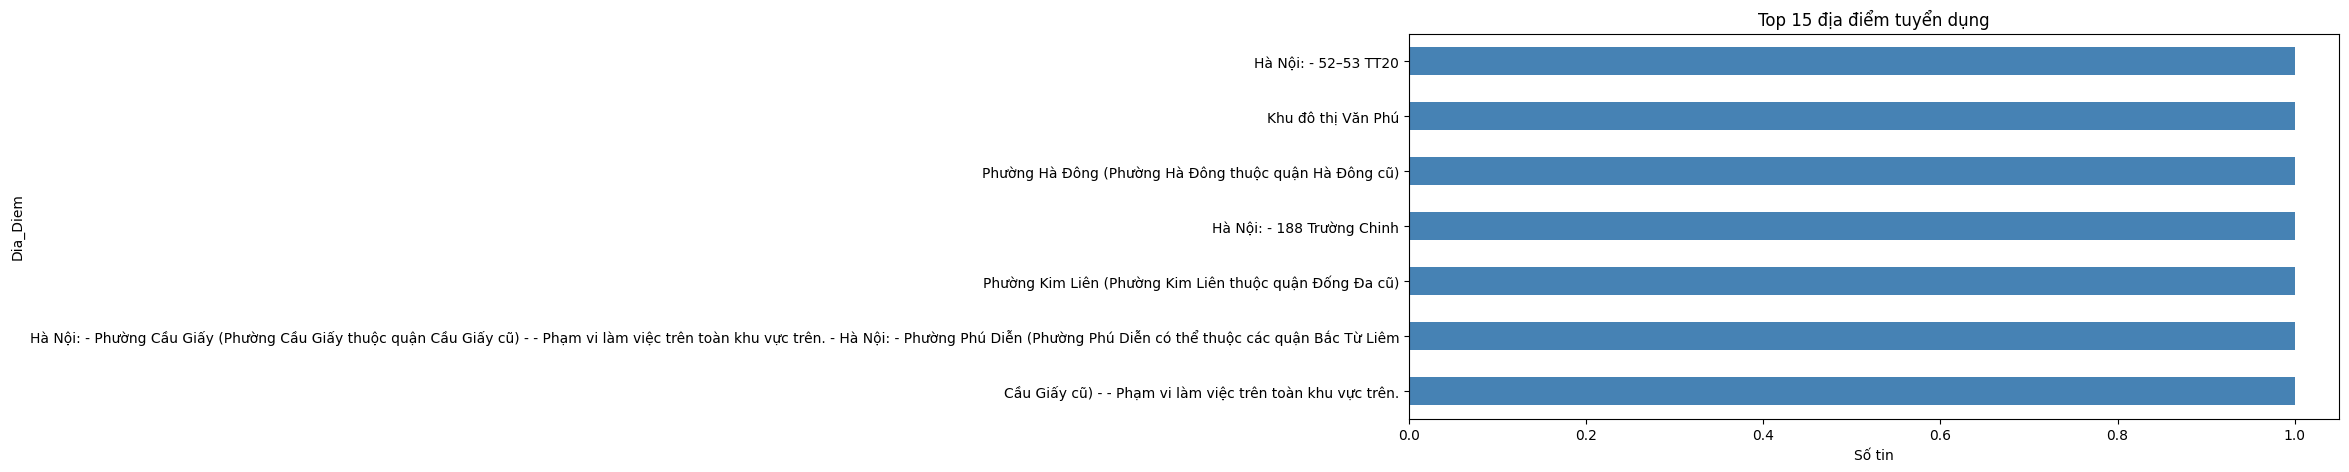

Dia_Diem
Hà Nội: - 52–53 TT20                                                                                                                                                                              1
Khu đô thị Văn Phú                                                                                                                                                                                1
Phường Hà Đông (Phường Hà Đông thuộc quận Hà Đông cũ)                                                                                                                                             1
Hà Nội: - 188 Trường Chinh                                                                                                                                                                        1
Phường Kim Liên (Phường Kim Liên thuộc quận Đống Đa cũ)                                                                                                                                           1
Hà Nội: - P

In [14]:
# Top 15 địa điểm tuyển dụng
if 'Dia_Diem' in df.columns:
    top_location = df['Dia_Diem'].dropna().str.split(',').explode().str.strip()
    top_location = top_location.value_counts().head(15)
    
    top_location.plot(kind='barh', color='steelblue')
    plt.title('Top 15 địa điểm tuyển dụng')
    plt.xlabel('Số tin')
    plt.gca().invert_yaxis()
    plt.tight_layout()
    plt.show()
    print(top_location)

## 4. Thống kê Mức lương

In [15]:
# Phân loại mức lương
if 'Muc_Luong_Goc' in df.columns:
    luong = df['Muc_Luong_Goc'].dropna()
    total = len(df)
    
    # Phân nhóm
    thoathuan = luong.str.contains('Thỏa thuận|Thoả thuận|thoa thuan', case=False, na=False).sum()
    co_so = total - thoathuan - luong.isnull().sum()
    
    print(f'  Thỏa thuận     : {thoathuan} tin ({thoathuan/total*100:.1f}%)')
    print(f'  Có mức lương cụ thể: {co_so} tin ({co_so/total*100:.1f}%)')
    print()
    print('--- Mẫu mức lương ---')
    print(luong[~luong.str.contains('Thỏa thuận|Thoả thuận', case=False, na=False)].head(20).to_string())

  Thỏa thuận     : 2 tin (66.7%)
  Có mức lương cụ thể: 1 tin (33.3%)

--- Mẫu mức lương ---
1    18 - 25 triệu


## 5. Thống kê Kinh nghiệm yêu cầu

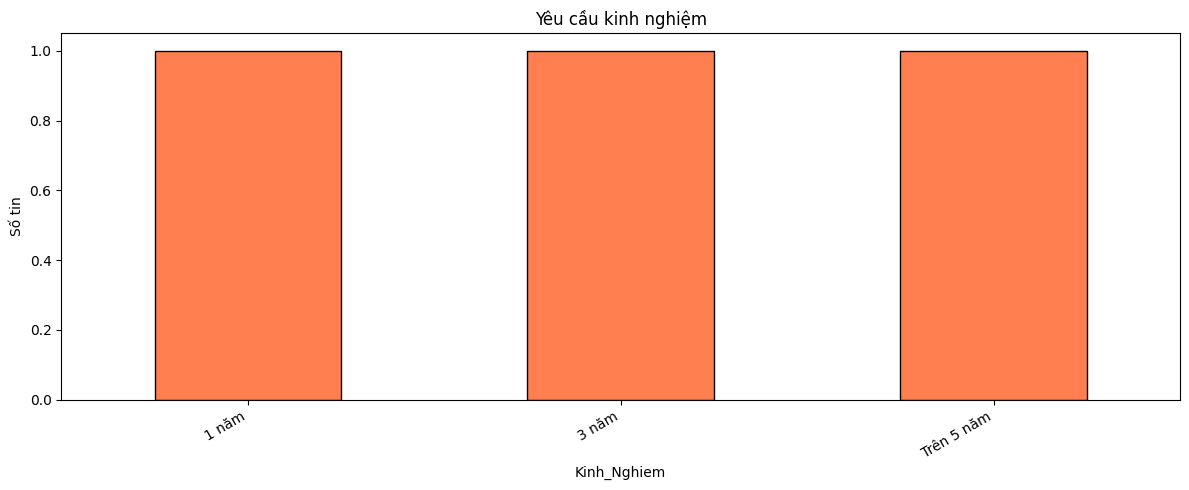

Kinh_Nghiem
1 năm         1
3 năm         1
Trên 5 năm    1
Name: count, dtype: int64


In [16]:
if 'Kinh_Nghiem' in df.columns:
    kn_counts = df['Kinh_Nghiem'].dropna().value_counts().head(12)
    
    kn_counts.plot(kind='bar', color='coral', edgecolor='black')
    plt.title('Yêu cầu kinh nghiệm')
    plt.ylabel('Số tin')
    plt.xticks(rotation=30, ha='right')
    plt.tight_layout()
    plt.show()
    print(kn_counts)

## 6. Top công ty tuyển dụng nhiều nhất

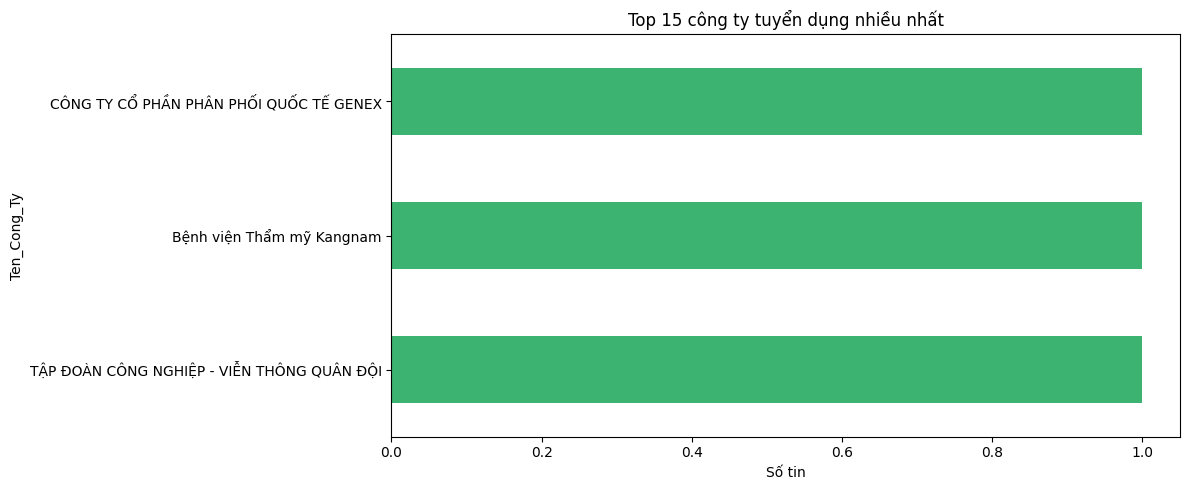

In [17]:
if 'Ten_Cong_Ty' in df.columns:
    top_cty = df['Ten_Cong_Ty'].dropna().value_counts().head(15)
    
    top_cty.plot(kind='barh', color='mediumseagreen')
    plt.title('Top 15 công ty tuyển dụng nhiều nhất')
    plt.xlabel('Số tin')
    plt.gca().invert_yaxis()
    plt.tight_layout()
    plt.show()

## 7. Tìm kiếm theo từ khóa trong Mô tả / Yêu cầu

In [18]:
# Tìm tin có yêu cầu kỹ năng cụ thể (thay đổi keyword bên dưới)
KEYWORD = 'Python'

mask = (
    df['Mo_Ta_Cong_Viec'].fillna('').str.contains(KEYWORD, case=False) |
    df['Yeu_Cau_Quyen_Loi'].fillna('').str.contains(KEYWORD, case=False)
)
result = df[mask][['Tieu_De', 'Ten_Cong_Ty', 'Muc_Luong_Goc', 'Dia_Diem']]
print(f'🔍 Tìm thấy {len(result)} tin có yêu cầu "{KEYWORD}"')
result.head(10)

🔍 Tìm thấy 2 tin có yêu cầu "Python"


,Tieu_De,Ten_Cong_Ty,Muc_Luong_Goc,Dia_Diem
0,Chuyên Viên Phân Tích Dữ Liệu / Data Analyst - Tại Hà Nội,CÔNG TY CỔ PHẦN PHÂN PHỐI QUỐC TẾ GENEX,Thoả thuận,"Hà Nội: - 52–53 TT20, Khu đô thị Văn Phú, Phường Hà Đông (Phường Hà Đông thu..."
1,Chuyên Viên Tổng Hợp Dữ Liệu Và Báo Cáo Quản Trị Thu Nhập 18 - 25M,Bệnh viện Thẩm mỹ Kangnam,18 - 25 triệu,"Hà Nội: - 188 Trường Chinh, Phường Kim Liên (Phường Kim Liên thuộc quận Đống..."


## 8. Xuất kết quả lọc ra file mới

In [19]:
# Lưu dữ liệu sạch (loại bỏ dòng không có tiêu đề)
df_clean = df.dropna(subset=['Tieu_De'])
df_clean.to_csv('raw_data_clean.csv', index=False, encoding='utf-8-sig')
print(f'✅ Đã lưu {len(df_clean)} tin vào raw_data_clean.csv')

✅ Đã lưu 3 tin vào raw_data_clean.csv
